We will now analyze the actual data

In [1]:
import h5py
import numpy as np
import pandas as pd
import scanpy as sc
from anndata.io import read_elem

In [2]:
with h5py.File(r"..\data\Full_cohort.h5ad", "r") as f:
    print('X type:', type(f['X']))  # Print the type of the 'X' dataset
    print(list(f.keys()))  # List the top-level groups in the HDF5 file
    print('obs keys:', list(f['obs'].keys()))  # List the keys in the 'obs' group
    print('var keys:', list(f['var'].keys()))  # List the keys in the 'var' group
    print('uns keys:', list(f['uns'].keys()))  # List the keys in the 'uns' group
    print('layers keys:', list(f['layers'].keys()))  # List the keys in the 'layers' group
    
    for layer in f['layers']:
        print('\n',layer)
        print(f"type of {layer}:", type(f['layers'][layer]))  # Print the type of each layer
        print(f"keys in {layer}:", list(f['layers'][layer].keys()))  # List the keys in each layer
        print(f"attributes of {layer}:", list(f['layers'][layer].attrs))  # List the attributes of each layer

X type: <class 'h5py._hl.group.Group'>
['X', 'layers', 'obs', 'obsm', 'obsp', 'uns', 'var', 'varm', 'varp']
obs keys: ['_index', 'category', 'conf_score', 'label', 'n_genes_by_counts', 'pct_counts_gene_group__mito_transcript', 'sanger_sample_id', 'total_counts']
var keys: ['_index', 'feature_types', 'gene_group__mito_protein', 'gene_group__mito_transcript', 'gene_group__ribo_protein', 'gene_group__ribo_rna', 'gene_symbols', 'log1p_mean_counts', 'log1p_total_counts', 'mean_counts', 'n_cells_by_counts', 'pct_dropout_by_counts', 'total_counts']
uns keys: ['log1p', 'log1p_cp10k']
layers keys: ['counts', 'log1p_cp10k']

 counts
type of counts: <class 'h5py._hl.group.Group'>
keys in counts: ['data', 'indices', 'indptr']
attributes of counts: ['encoding-type', 'encoding-version', 'shape']

 log1p_cp10k
type of log1p_cp10k: <class 'h5py._hl.group.Group'>
keys in log1p_cp10k: ['data', 'indices', 'indptr']
attributes of log1p_cp10k: ['encoding-type', 'encoding-version', 'shape']


In [3]:
with h5py.File(r"..\data\Full_cohort.h5ad", "r") as f:
    print(f"Shape of X: {f['X'].attrs['shape']}")  # Print the shape of the 'X' dataset
    print(f"Shape of layer counts: {f['layers']['counts'].attrs['shape']}")  # Print the shape of the 'counts' layer
    print(f"Shape of layer log1p_cp10k: {f['layers']['log1p_cp10k'].attrs['shape']}")  # Print the shape of the 'logcounts' layer

Shape of X: [1185861   33538]
Shape of layer counts: [1185861   33538]
Shape of layer log1p_cp10k: [1185861   33538]


In [4]:
with h5py.File(r"..\data\Full_cohort.h5ad", "r") as f:
    obs = read_elem(f['obs'])
    var = read_elem(f['var'])
    print(type(obs))
    print(obs.shape)
    print(type(var))
    print(var.shape)

<class 'pandas.DataFrame'>
(1185861, 7)
<class 'pandas.DataFrame'>
(33538, 12)


In [5]:
obs.head()

,sanger_sample_id,pct_counts_gene_group__mito_transcript,n_genes_by_counts,total_counts,label,category,conf_score
TCAGGTATCCGACATA-1-5892STDY10205765__41618__cellranger720_count_5892STDY10205765_GRCh38-3_0_0,5892STDY10205765,0.886711,4250,141196.0,Enterocytes progenitor crypt GPX2+,Enterocyte,0.9987180652351288
CCAATTTAGATACCAA-1-5892STDY10205765__41618__cellranger720_count_5892STDY10205765_GRCh38-3_0_0,5892STDY10205765,0.929196,4671,108158.0,Enterocytes progenitor crypt GPX2+,Enterocyte,0.9972390415425336
CATGAGTCAGGCATTT-1-5892STDY10205765__41618__cellranger720_count_5892STDY10205765_GRCh38-3_0_0,5892STDY10205765,0.686976,4169,107864.0,Enterocytes progenitor crypt GPX2+,Enterocyte,0.9770095240845306
TCTCACGGTATCTCGA-1-5892STDY10205765__41618__cellranger720_count_5892STDY10205765_GRCh38-3_0_0,5892STDY10205765,0.361118,2867,81137.0,Enterocytes progenitor crypt GPX2+,Enterocyte,0.772354776734459
TGCGGCAGTCCCAAAT-1-5892STDY10205765__41618__cellranger720_count_5892STDY10205765_GRCh38-3_0_0,5892STDY10205765,0.717362,2527,79876.0,Enterocytes progenitor crypt GPX2+,Enterocyte,0.98518622462155


In [6]:
obs['category'].value_counts()

category
T cell           295801
Enterocyte       279908
Secretory        164072
B cell           141436
Plasma B cell    125847
Myeloid           87565
Stem cell         79946
Mesenchymal       11286
Name: count, dtype: int64

<Axes: >

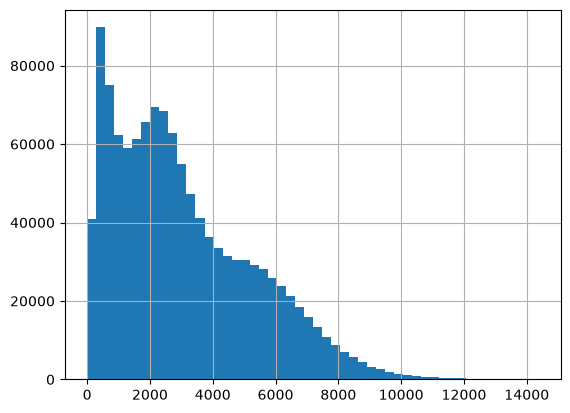

In [7]:
obs['n_genes_by_counts'].hist(bins=50)

In [8]:
obs.info()

<class 'pandas.DataFrame'>
Index: 1185861 entries, TCAGGTATCCGACATA-1-5892STDY10205765__41618__cellranger720_count_5892STDY10205765_GRCh38-3_0_0 to GAGATGGCAAGAGAGA-1-scrnacdb9997594__37295__cellranger720_count_37295_scrnacdb9997594_GRCh38-3_0_0
Data columns (total 7 columns):
 #   Column                                  Non-Null Count    Dtype   
---  ------                                  --------------    -----   
 0   sanger_sample_id                        1185861 non-null  category
 1   pct_counts_gene_group__mito_transcript  1185861 non-null  float32 
 2   n_genes_by_counts                       1185861 non-null  int32   
 3   total_counts                            1185861 non-null  float32 
 4   label                                   1185861 non-null  category
 5   category                                1185861 non-null  category
 6   conf_score                              1185861 non-null  category
dtypes: category(4), float32(2), int32(1)
memory usage: 72.9+ MB


In [9]:
obs.describe()

,pct_counts_gene_group__mito_transcript,n_genes_by_counts,total_counts
count,1.185861e+06,1.185861e+06,1.185861e+06
mean,1.289395e+01,3.074326e+03,1.448019e+04
std,1.332018e+01,2.209982e+03,1.970805e+04
min,0.000000e+00,4.000000e+00,1.400000e+01
25%,3.673958e+00,1.290000e+03,2.785000e+03
50%,8.296428e+00,2.593000e+03,7.051000e+03
75%,1.818182e+01,4.508000e+03,2.015400e+04
max,7.999464e+01,1.436400e+04,9.220330e+05


In [10]:
var.head()

,gene_symbols,feature_types,gene_group__mito_transcript,gene_group__mito_protein,gene_group__ribo_protein,gene_group__ribo_rna,n_cells_by_counts,mean_counts,log1p_mean_counts,pct_dropout_by_counts,total_counts,log1p_total_counts
ENSG00000243485,MIR1302-2HG,Gene Expression,False,False,False,False,45,1.556939e-05,1.556927e-05,99.998443,45.0,3.828641
ENSG00000237613,FAM138A,Gene Expression,False,False,False,False,2,6.919731e-07,6.919728e-07,99.999931,2.0,1.098612
ENSG00000186092,OR4F5,Gene Expression,False,False,False,False,2,6.919731e-07,6.919728e-07,99.999931,2.0,1.098612
ENSG00000238009,AL627309.1,Gene Expression,False,False,False,False,9340,3.329082e-03,3.323553e-03,99.676849,9622.0,9.171911
ENSG00000239945,AL627309.3,Gene Expression,False,False,False,False,532,1.840648e-04,1.840479e-04,99.981594,532.0,6.278522


In [11]:
var['feature_types'].value_counts()

feature_types
Gene Expression    33538
Name: count, dtype: int64

In [12]:
var['gene_group__mito_transcript'].value_counts()

gene_group__mito_transcript
False    33525
True        13
Name: count, dtype: int64

In [13]:
var['gene_group__ribo_protein'].value_counts()

gene_group__ribo_protein
False    33374
True       164
Name: count, dtype: int64

In [14]:
var['gene_group__ribo_rna'].value_counts()

gene_group__ribo_rna
False    33538
Name: count, dtype: int64

In [15]:
var['pct_dropout_by_counts'].describe()

count    33538.000000
mean        94.788122
std          8.736940
min          7.905238
25%         92.570977
50%         99.489774
75%         99.972425
max        100.000000
Name: pct_dropout_by_counts, dtype: float64

Join metadata to obs

In [16]:
# check if sample ids in metadata match the sample ids in the expression matrix
mapped_df = pd.read_csv(r"..\data\mapped_data.tsv", sep="\t", index_col=0)
sample_ids_in_metadata = set(mapped_df.index)
sample_ids_in_expression_matrix =  set(obs['sanger_sample_id'])

# Find the intersection of sample IDs
common_sample_ids = sample_ids_in_metadata & sample_ids_in_expression_matrix

# Find the difference of sample IDs
only_in_metadata = sample_ids_in_metadata - sample_ids_in_expression_matrix
only_in_expression_matrix = sample_ids_in_expression_matrix - sample_ids_in_metadata

In [17]:
print(f"Number of sample IDs in metadata: {len(sample_ids_in_metadata)}")
print(f"Number of sample IDs in expression matrix: {len(sample_ids_in_expression_matrix)}")
print(f"Number of common sample IDs: {len(common_sample_ids)}")
print(f"Number of sample IDs only in metadata: {len(only_in_metadata)}")
print(f"Number of sample IDs only in expression matrix: {len(only_in_expression_matrix)}")

Number of sample IDs in metadata: 343
Number of sample IDs in expression matrix: 343
Number of common sample IDs: 343
Number of sample IDs only in metadata: 0
Number of sample IDs only in expression matrix: 0


In [18]:
sample_ids_common = obs['sanger_sample_id'].isin(mapped_df.index).sum()
sample_ids_not_common = (~obs['sanger_sample_id'].isin(mapped_df.index)).sum()
print(sample_ids_common, sample_ids_not_common)

1185861 0


In [19]:
mapped_df.head()

,biopsy_type,bead_version,bead_lot,chip_version,chip_lot,enzyme_lot_BLP,gem_lot,f2_f1_ratio,individual_id,disease_status,age_binned_10,sex,ti_ses_inflamed
sanger_sample_id,,,,,,,,,,,,,
5892STDY10205765,terminal ileum,V3.1,NaN,chip-g,lot_160047,SLCB6672,lot_155287,04:01:00,IBDverse-1-3A5C2FF82FA8A4,CD,40.0,male,inflamed
5892STDY10315937,terminal ileum,V3.1,lot_160848,chip-g,lot_160047,SLCD4967,lot_160900,01:00:00,IBDverse-1-0DD5B680D0BFFB,CD,60.0,male,inflamed
5892STDY10315938,terminal ileum,V3.1,lot_160848,chip-g,lot_160047,SLCD4967,lot_160900,01:00:00,IBDverse-1-B257F708E64F29,CD,30.0,female,inflamed
5892STDY10653007,terminal ileum,V3.1,lot_160848,chip-g,lot_160047,SLCD4967,lot_160900,04:01:00,IBDverse-1-8D29C5BD7C12C7,CD,40.0,female,inflamed
5892STDY10653009,terminal ileum,V3.1,lot_160848,chip-g,lot_160673,SLCD4967,lot_160851,01:00:00,IBDverse-1-B45A577AF0E969,CD,30.0,female,inflamed


In [20]:
obs.head()

,sanger_sample_id,pct_counts_gene_group__mito_transcript,n_genes_by_counts,total_counts,label,category,conf_score
TCAGGTATCCGACATA-1-5892STDY10205765__41618__cellranger720_count_5892STDY10205765_GRCh38-3_0_0,5892STDY10205765,0.886711,4250,141196.0,Enterocytes progenitor crypt GPX2+,Enterocyte,0.9987180652351288
CCAATTTAGATACCAA-1-5892STDY10205765__41618__cellranger720_count_5892STDY10205765_GRCh38-3_0_0,5892STDY10205765,0.929196,4671,108158.0,Enterocytes progenitor crypt GPX2+,Enterocyte,0.9972390415425336
CATGAGTCAGGCATTT-1-5892STDY10205765__41618__cellranger720_count_5892STDY10205765_GRCh38-3_0_0,5892STDY10205765,0.686976,4169,107864.0,Enterocytes progenitor crypt GPX2+,Enterocyte,0.9770095240845306
TCTCACGGTATCTCGA-1-5892STDY10205765__41618__cellranger720_count_5892STDY10205765_GRCh38-3_0_0,5892STDY10205765,0.361118,2867,81137.0,Enterocytes progenitor crypt GPX2+,Enterocyte,0.772354776734459
TGCGGCAGTCCCAAAT-1-5892STDY10205765__41618__cellranger720_count_5892STDY10205765_GRCh38-3_0_0,5892STDY10205765,0.717362,2527,79876.0,Enterocytes progenitor crypt GPX2+,Enterocyte,0.98518622462155


In [21]:
obs = obs.join(mapped_df, on='sanger_sample_id', how='left')

In [22]:
obs.shape

(1185861, 20)

In [23]:
obs.describe()

,pct_counts_gene_group__mito_transcript,n_genes_by_counts,total_counts,age_binned_10
count,1.185861e+06,1.185861e+06,1.185861e+06,1.180011e+06
mean,1.289395e+01,3.074326e+03,1.448019e+04,4.498696e+01
std,1.332018e+01,2.209982e+03,1.970805e+04,1.341215e+01
min,0.000000e+00,4.000000e+00,1.400000e+01,2.000000e+01
25%,3.673958e+00,1.290000e+03,2.785000e+03,4.000000e+01
50%,8.296428e+00,2.593000e+03,7.051000e+03,4.000000e+01
75%,1.818182e+01,4.508000e+03,2.015400e+04,6.000000e+01
max,7.999464e+01,1.436400e+04,9.220330e+05,7.000000e+01


In [24]:
obs.info()

<class 'pandas.DataFrame'>
Index: 1185861 entries, TCAGGTATCCGACATA-1-5892STDY10205765__41618__cellranger720_count_5892STDY10205765_GRCh38-3_0_0 to GAGATGGCAAGAGAGA-1-scrnacdb9997594__37295__cellranger720_count_37295_scrnacdb9997594_GRCh38-3_0_0
Data columns (total 20 columns):
 #   Column                                  Non-Null Count    Dtype   
---  ------                                  --------------    -----   
 0   sanger_sample_id                        1185861 non-null  str     
 1   pct_counts_gene_group__mito_transcript  1185861 non-null  float32 
 2   n_genes_by_counts                       1185861 non-null  int32   
 3   total_counts                            1185861 non-null  float32 
 4   label                                   1185861 non-null  category
 5   category                                1185861 non-null  category
 6   conf_score                              1185861 non-null  category
 7   biopsy_type                             1185861 non-null  str     
 

In [34]:
obs.isna().sum()

sanger_sample_id                                0
pct_counts_gene_group__mito_transcript          0
n_genes_by_counts                               0
total_counts                                    0
label                                           0
category                                        0
conf_score                                      0
biopsy_type                                     0
bead_version                                13906
bead_lot                                    36603
chip_version                                18748
chip_lot                                    38950
enzyme_lot_BLP                              12864
gem_lot                                     21278
f2_f1_ratio                                908020
individual_id                                5850
disease_status                               5850
age_binned_10                                5850
sex                                          5850
ti_ses_inflamed                              5850


In [25]:
# rows with no induvidual information
no_individual_info = obs[obs['individual_id'].isnull()]
print(f"Number of rows with no individual information: {no_individual_info.shape[0]}")
no_individual_info.head()

Number of rows with no individual information: 5850


,sanger_sample_id,pct_counts_gene_group__mito_transcript,n_genes_by_counts,total_counts,label,category,conf_score,biopsy_type,bead_version,bead_lot,chip_version,chip_lot,enzyme_lot_BLP,gem_lot,f2_f1_ratio,individual_id,disease_status,age_binned_10,sex,ti_ses_inflamed
GCAGTTACAACTACGT-1-5892STDY8357646__32143__cellranger720_count_32143_5892STDY8357646_GRCh38-3_0_0,5892STDY8357646,16.944153,13947,746464.0,Enterocytes precursor crypt KRT20+,Enterocyte,0.5719429835291151,terminal ileum,V3,lot_154306,chip-b,lot_153745,SLBZ4589,lot_154140,01:00:00,NaN,NaN,NaN,NaN,NaN
GTCCTCAGTTCTGACA-1-5892STDY8357646__32143__cellranger720_count_32143_5892STDY8357646_GRCh38-3_0_0,5892STDY8357646,13.207969,11945,586661.0,Enterocytes precursor crypt KRT20+,Enterocyte,0.9317621641200352,terminal ileum,V3,lot_154306,chip-b,lot_153745,SLBZ4589,lot_154140,01:00:00,NaN,NaN,NaN,NaN,NaN
GACTGATAGTGCTACT-1-5892STDY8357646__32143__cellranger720_count_32143_5892STDY8357646_GRCh38-3_0_0,5892STDY8357646,11.196731,12443,583072.0,Enterocytes precursor crypt KRT20+,Enterocyte,0.999254100432725,terminal ileum,V3,lot_154306,chip-b,lot_153745,SLBZ4589,lot_154140,01:00:00,NaN,NaN,NaN,NaN,NaN
CTCGAGGCACTGTGTA-1-5892STDY8357646__32143__cellranger720_count_32143_5892STDY8357646_GRCh38-3_0_0,5892STDY8357646,18.605526,12746,491655.0,Enterocytes precursor crypt KRT20+,Enterocyte,0.9946284444597993,terminal ileum,V3,lot_154306,chip-b,lot_153745,SLBZ4589,lot_154140,01:00:00,NaN,NaN,NaN,NaN,NaN
CAGCAATTCGCCTTTG-1-5892STDY8357646__32143__cellranger720_count_32143_5892STDY8357646_GRCh38-3_0_0,5892STDY8357646,11.755560,12888,373653.0,Enterocytes progenitor crypt OLFM4-hi,Enterocyte,0.9607802376440736,terminal ileum,V3,lot_154306,chip-b,lot_153745,SLBZ4589,lot_154140,01:00:00,NaN,NaN,NaN,NaN,NaN


In [26]:
no_individual_info['sanger_sample_id'].value_counts()

sanger_sample_id
5892STDY8357646    5850
Name: count, dtype: int64

In [27]:
print('unique samples:', obs['sanger_sample_id'].nunique())
print('unique individuals:', obs['individual_id'].nunique())

unique samples: 343
unique individuals: 342


In [28]:
obs.groupby('individual_id')['ti_ses_inflamed'].value_counts()

individual_id              ti_ses_inflamed
IBDverse-1-0045EBB9CBFB5F  uninflamed          2578
IBDverse-1-007DB71942EA7A  inflamed            4421
IBDverse-1-0150BDB36ABEBC  uninflamed           750
IBDverse-1-01C1EA8FD8CD67  uninflamed          2314
IBDverse-1-0244A66A937BB2  uninflamed          2111
                                              ...  
IBDverse-1-FD83BCEFAABFB2  inflamed            3890
IBDverse-1-FDAEA4F2BDD773  uninflamed          1009
IBDverse-1-FDD4FC929E8E2B  uninflamed         11252
IBDverse-1-FE8B7C0FF5543B  uninflamed          2493
IBDverse-1-FF6664E682D990  inflamed            4513
Name: count, Length: 342, dtype: int64

Combining ti_ses_inflamed and disease_status into one because healthy always has uninfammed gut as shown in metadata anlysis

In [29]:
obs['health_category'] = list(zip(obs['disease_status'], obs['ti_ses_inflamed']))
x = set(obs['health_category'])
print(x)


{('Healthy', 'uninflamed'), ('CD', 'inflamed'), ('CD', 'uninflamed'), (nan, nan)}


In [33]:
obs['health_category'] = obs['health_category'].map({
    ('Healthy', 'uninflamed'): 'Healthy',
    ('CD', 'inflamed'): 'CD inflamed',
    ('CD', 'uninflamed'): 'CD uninflamed',
})

In [31]:
obs['health_category'].value_counts()

health_category
Healthy          619805
CD inflamed      307880
CD uninflamed    252326
Name: count, dtype: int64